# Hafta 4 · Sınıflandırma

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde lojistik regresyon, k-NN ve karar ağacı hesaplarını notlardaki çözümlü örneklerle karşılaştıracak, ardından Iris veri setinde beş sınıflandırıcıyı yarıştıracaksınız.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Lojistik regresyon: sigmoid ve çapraz entropi
Çözümlü Örnek 4.1 (geçme olasılığı) ve 4.2 (kayıp hesabı).

In [2]:
import numpy as np
sigmoid = lambda z: 1 / (1 + np.exp(-z))

for x in [3, 4, 5]:                     # Örnek 4.1: σ(1.5x − 6)
    p = sigmoid(1.5 * x - 6)
    print(f"x={x}: p={p:.3f}", "geçer" if p >= 0.5 else "kalır")
for p in [0.9, 0.1]:                    # Örnek 4.2: y = 1 için kayıp
    print(f"p={p} → L = −ln p = {-np.log(p):.3f}")

x=3: p=0.182 kalır
x=4: p=0.500 geçer
x=5: p=0.818 geçer
p=0.9 → L = −ln p = 0.105
p=0.1 → L = −ln p = 2.303


### Bir gradyan iniş adımı
Çapraz entropinin gradyanı: ∂L/∂w = (p̂ − y)·x ve ∂L/∂b = p̂ − y.

In [3]:
w, b = np.array([0.5, -1.0]), 0.0
x, y, eta = np.array([2.0, 1.0]), 1, 0.1
p = sigmoid(w @ x + b)
print(f"önce : p={p:.3f}, kayıp={-np.log(p):.3f}")
w = w - eta * (p - y) * x              # ∂L/∂w = (p − y) x
b = b - eta * (p - y)                  # ∂L/∂b = p − y
p = sigmoid(w @ x + b)
print("w =", w, " b =", b)
print(f"sonra: p={p:.3f}, kayıp={-np.log(p):.3f}")

önce : p=0.500, kayıp=0.693
w = [ 0.6  -0.95]  b = 0.05
sonra: p=0.574, kayıp=0.554


### Alıştırma (Değerlendirme Sorusu 12)
w = [1, −1], b = 0, x = [1, 2], y = 0 ve η = 0.5 için bir gradyan adımı uygulayın. Önce elle çözün, sonra çalıştırın.

In [ ]:
w, b = np.array([1.0, -1.0]), 0.0
x, y, eta = np.array([1.0, 2.0]), 0, 0.5
p = sigmoid(w @ x + b)
print(f"önce : p={p:.3f}, kayıp={-np.log(1 - p):.3f}")
w, b = w - eta * (p - y) * x, b - eta * (p - y)
p = sigmoid(w @ x + b)
print("w =", w.round(3), " b =", round(b, 3))
print(f"sonra: p={p:.3f}, kayıp={-np.log(1 - p):.3f}")

## 2. k-en yakın komşu (Çözümlü Örnek 4.3)
Yeni film q = (5, 4): aksiyon ve romantik sahne sayıları.

In [5]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
X_film = np.array([[7, 3], [6, 1], [8, 4], [4, 5], [2, 7], [1, 8]])
y_film = ["Aksiyon"] * 3 + ["Romantik"] * 3
yeni = np.array([[5, 4]])

d = np.linalg.norm(X_film - yeni, axis=1)      # Öklid uzaklıkları
for ad, uz in zip(["A1", "A2", "A3", "R1", "R2", "R3"], d):
    print(f"{ad}: {uz:.3f}")
for k in [1, 3]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_film, y_film)
    print(f"k = {k} → tahmin: {knn.predict(yeni)[0]}")

A1: 2.236
A2: 3.162
A3: 3.000
R1: 1.414
R2: 4.243
R3: 5.657
k = 1 → tahmin: Romantik
k = 3 → tahmin: Aksiyon


### Alıştırma (Değerlendirme Sorusu 9)
Yeni film (3, 5) olsaydı k = 3 için tahmin ne olurdu? Uzaklıkları önce elle hesaplayın.

In [ ]:
yeni2 = np.array([[3, 5]])
print(np.linalg.norm(X_film - yeni2, axis=1).round(3))
print(KNeighborsClassifier(n_neighbors=3).fit(X_film, y_film).predict(yeni2))

## 3. Karar ağaçları
### Bilgi kazancı (Çözümlü Örnek 4.4)

In [7]:
import numpy as np
def H(*n):                              # sınıf sayılarından entropi
    p = np.array(n) / sum(n); p = p[p > 0]
    return -(p * np.log2(p)).sum()
ig_devam = H(6, 4) - (0.6 * H(5, 1) + 0.4 * H(1, 3))
ig_odev = H(6, 4) - (0.5 * H(4, 1) + 0.5 * H(2, 3))
print(f"H(kök) = {H(6, 4):.3f}")
print(f"IG(Devam) = {ig_devam:.3f}\nIG(Ödev)  = {ig_odev:.3f}")

H(kök) = 0.971
IG(Devam) = 0.256
IG(Ödev)  = 0.125


### Sürekli öznitelikte eşik seçimi (Çözümlü Örnek 4.5)
scikit-learn'ün karar ağacı (CART) varsayılan olarak Gini safsızlığını kullanır.

In [8]:
from sklearn.tree import DecisionTreeClassifier, export_text
x = np.array([[1], [2], [3], [4], [5], [6], [7]])
y = np.array([0, 0, 0, 1, 0, 1, 1])
agac = DecisionTreeClassifier(random_state=0).fit(x, y)
print(export_text(agac, feature_names=["x"]))

|--- x <= 3.50
|   |--- class: 0
|--- x >  3.50
|   |--- x <= 5.50
|   |   |--- x <= 4.50
|   |   |   |--- class: 1
|   |   |--- x >  4.50
|   |   |   |--- class: 0
|   |--- x >  5.50
|   |   |--- class: 1



## 4. Iris veri setinde beş sınıflandırıcı
150 çiçek, 4 öznitelik, 3 tür. Veri %70 eğitim / %30 test olarak katmanlı (stratify) bölünür.

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

X, y = load_iris(return_X_y=True)             # 150 çiçek, 4 öznitelik, 3 tür
X_egt, X_test, y_egt, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0)
print("eğitim:", X_egt.shape, " test:", X_test.shape)

eğitim: (105, 4)  test: (45, 4)


In [10]:
modeller = {
    "Lojistik regresyon": make_pipeline(StandardScaler(), LogisticRegression()),
    "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "Karar ağacı": DecisionTreeClassifier(max_depth=3, random_state=0),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
}
for ad, model in modeller.items():
    model.fit(X_egt, y_egt)
    print(f"{ad:20s} test doğruluğu: {model.score(X_test, y_test):.3f}")

Lojistik regresyon   test doğruluğu: 0.978
k-NN (k=5)           test doğruluğu: 0.978
Karar ağacı          test doğruluğu: 0.956
Naive Bayes          test doğruluğu: 0.978
SVM (RBF)            test doğruluğu: 0.978


### Karar sınırlarını görmek
Aynı modelleri iki boyutlu “iki ay” verisinde eğitip öğrendikleri bölgeleri çizelim (Şekil 4.7'deki deneyin benzeri).

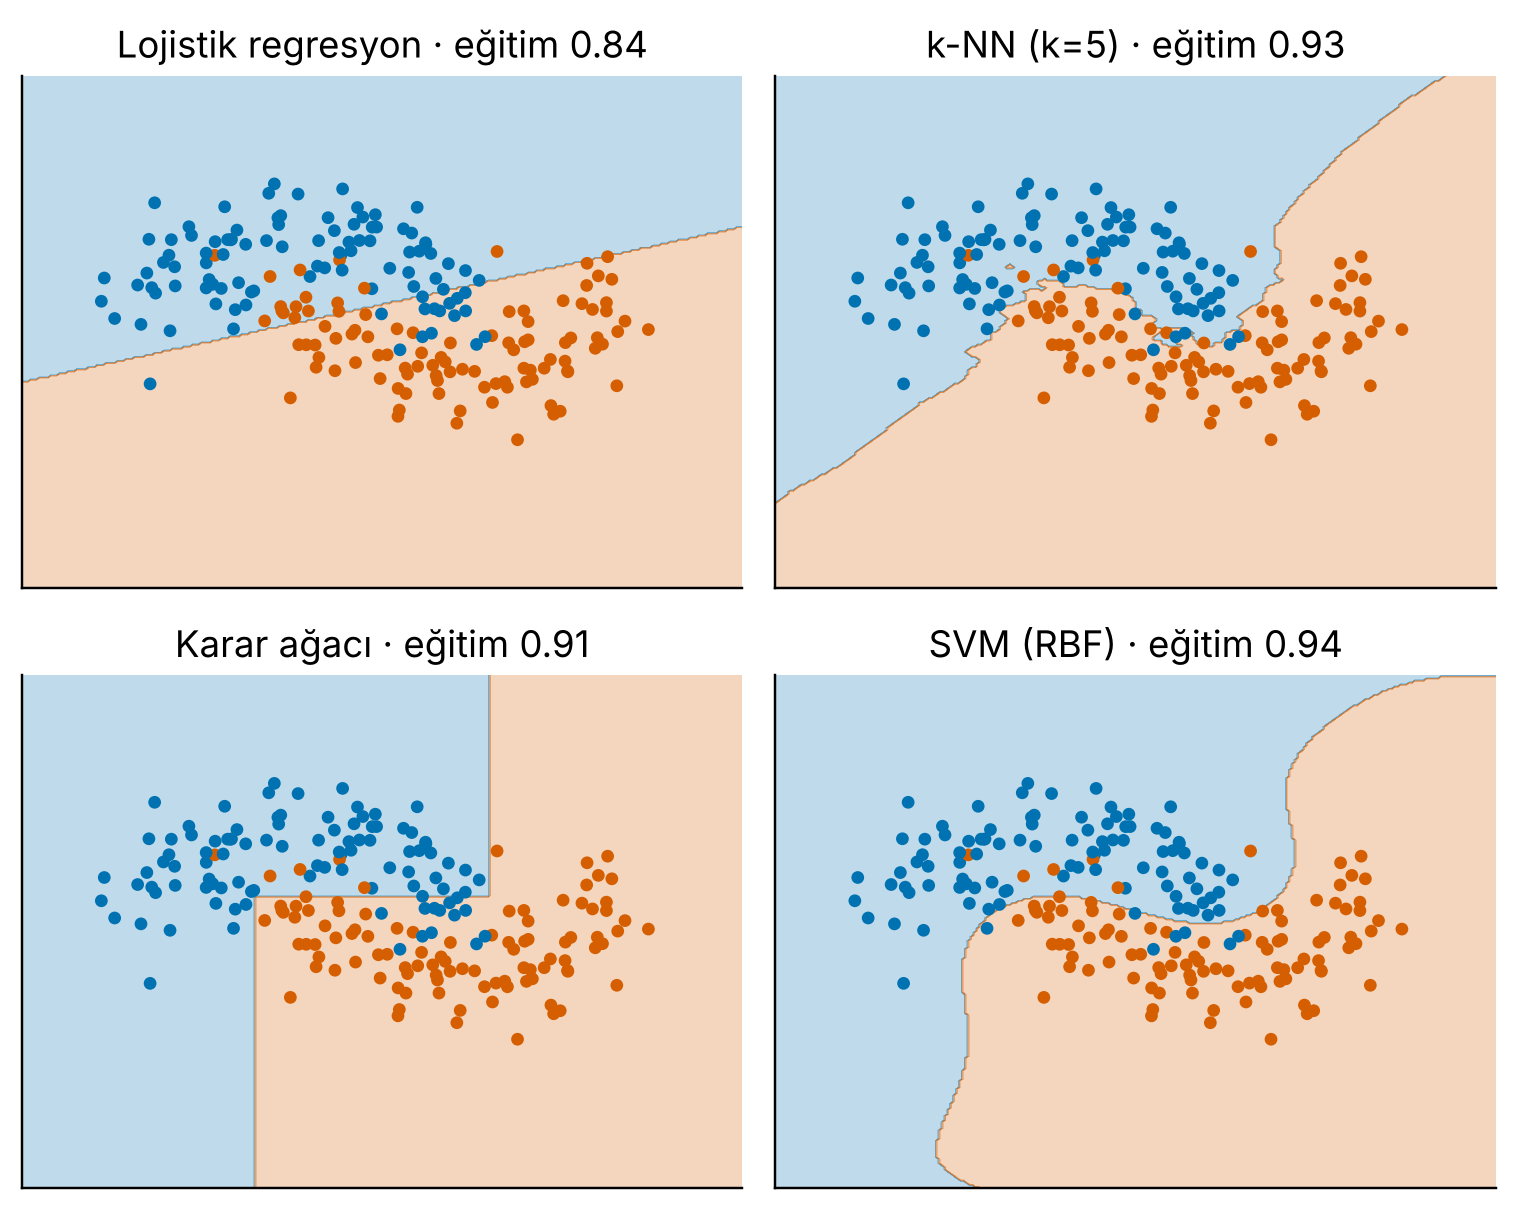

In [11]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons
Xm, ym = make_moons(200, noise=0.25, random_state=0)
g = np.linspace(-2, 3, 250)
xx, yy = np.meshgrid(g, g - 0.5)            # tahmin ızgarası
P = np.c_[xx.ravel(), yy.ravel()]
renk = ListedColormap(["#0072B2", "#D55E00"])
fig, eks = plt.subplots(2, 2, figsize=(7, 5.6))
for ax, ad in zip(eks.ravel(), ["Lojistik regresyon",
                  "k-NN (k=5)", "Karar ağacı", "SVM (RBF)"]):
    m = modeller[ad].fit(Xm, ym)
    Z = m.predict(P).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=renk)
    ax.scatter(*Xm.T, c=ym, s=10, cmap=renk)
    ax.set_title(f"{ad} · eğitim {m.score(Xm, ym):.2f}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()